In [1]:
import random, numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import torchvision, torchvision.transforms as T
from torch.utils.data import DataLoader, random_split, Subset
import matplotlib.pyplot as plt
from tqdm import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

device: cuda


In [2]:
full_train = torchvision.datasets.CIFAR10('./data', train=True, download=True, transform=T.ToTensor())
test_set = torchvision.datasets.CIFAR10('./data', train=False, download=True, transform=T.ToTensor())

train_set, val_set = random_split(full_train, [40000, 10000],
                                  generator=torch.Generator().manual_seed(SEED))
train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
val_loader = DataLoader(val_set, batch_size=256)
test_loader = DataLoader(test_set, batch_size=256)

attack_loader = DataLoader(Subset(test_set, range(2000)), batch_size=250)

100%|██████████| 170M/170M [39:42<00:00, 71.6kB/s]


In [3]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.register_buffer('mean', torch.tensor([0.4914, 0.4822, 0.4465]).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor([0.2470, 0.2435, 0.2616]).view(1, 3, 1, 1))
        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.fc = nn.Sequential(
            nn.Flatten(), nn.Linear(128 * 4 * 4, 256), nn.ReLU(), nn.Dropout(0.5), nn.Linear(256, 10)
        )

    def forward(self, x):
        x = (x - self.mean) / self.std
        return self.fc(self.conv(x))

In [4]:
def fgsm(model, x, y, eps):
    x = x.clone().detach().requires_grad_(True)
    loss = F.cross_entropy(model(x), y)
    grad, = torch.autograd.grad(loss, x)
    return (x + eps * grad.sign()).clamp(0, 1).detach()

def pgd(model, x, y, eps, steps=10, alpha=None):
    alpha = alpha or eps / 4
    x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1)
    for _ in range(steps):
        x_adv.requires_grad_(True)
        loss = F.cross_entropy(model(x_adv), y)
        grad, = torch.autograd.grad(loss, x_adv)
        x_adv = x_adv.detach() + alpha * grad.sign()
        x_adv = torch.min(torch.max(x_adv, x - eps), x + eps).clamp(0, 1)
    return x_adv.detach()

def accuracy(model, loader, attack=None, eps=0.0):
    model.eval()
    correct = total = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        if attack is not None and eps > 0:
            x = attack(model, x, y, eps)
        with torch.no_grad():
            correct += (model(x).argmax(1) == y).sum().item()
        total += y.size(0)
    return correct / total

In [5]:
def train(model, epochs=10, lr=1e-3, adv_eps=None):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for ep in range(epochs):
        model.train()
        for x, y in tqdm(train_loader, desc=f'epoch {ep+1}/{epochs}', leave=False):
            x, y = x.to(device), y.to(device)
            if adv_eps is not None:
                model.eval()
                x_adv = fgsm(model, x, y, adv_eps)
                model.train()
                x, y = torch.cat([x, x_adv]), torch.cat([y, y])
            loss = F.cross_entropy(model(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
        print(f'epoch {ep+1}: val acc = {accuracy(model, val_loader):.4f}')
    return model

model_clean = train(Net().to(device))
print('Test accuracy (чистые данные):', accuracy(model_clean, test_loader))
torch.save(model_clean.state_dict(), 'model_clean.pt')

epoch 1: val acc = 0.5648


epoch 2: val acc = 0.6427


epoch 3: val acc = 0.6584


epoch 4: val acc = 0.7084


epoch 5: val acc = 0.7275


epoch 6: val acc = 0.7447


epoch 7: val acc = 0.7532


epoch 8: val acc = 0.7591


epoch 9: val acc = 0.7583


epoch 10: val acc = 0.7569
Test accuracy (чистые данные): 0.7554


In [6]:
EPS = [0, 1/255, 2/255, 4/255, 8/255, 16/255]

def robustness_curve(model):
    return {
        'FGSM': [accuracy(model, attack_loader, fgsm, e) for e in EPS],
        'PGD':  [accuracy(model, attack_loader, pgd, e) for e in EPS],
    }

curve_clean = robustness_curve(model_clean)
for name, accs in curve_clean.items():
    print(name, [f'{a:.3f}' for a in accs])

FGSM ['0.770', '0.544', '0.361', '0.169', '0.044', '0.012']
PGD ['0.770', '0.507', '0.283', '0.064', '0.003', '0.000']


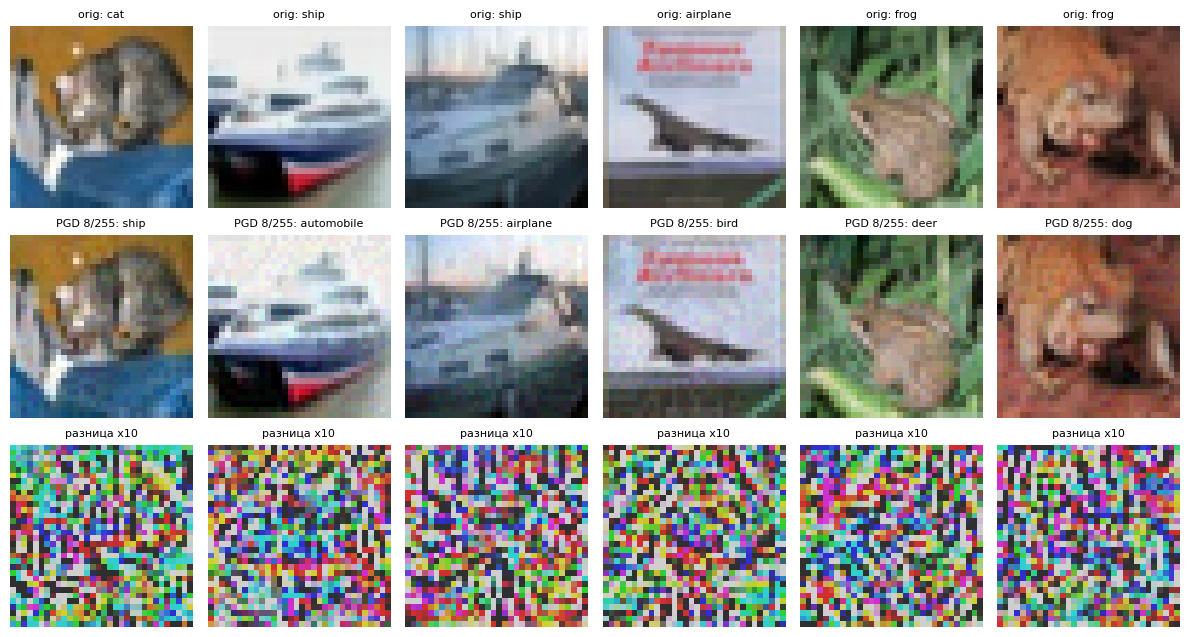

In [7]:
classes = test_set.classes
x, y = next(iter(attack_loader))
x, y = x[:6].to(device), y[:6].to(device)
x_adv = pgd(model_clean, x, y, 8/255)
with torch.no_grad():
    p0, p1 = model_clean(x).argmax(1), model_clean(x_adv).argmax(1)

fig, ax = plt.subplots(3, 6, figsize=(12, 6.5))
for i in range(6):
    ax[0, i].imshow(x[i].cpu().permute(1, 2, 0)); ax[0, i].set_title(f'orig: {classes[p0[i]]}', fontsize=8)
    ax[1, i].imshow(x_adv[i].cpu().permute(1, 2, 0)); ax[1, i].set_title(f'PGD 8/255: {classes[p1[i]]}', fontsize=8)
    diff = ((x_adv[i] - x[i]).cpu() * 10 + 0.5).clamp(0, 1)
    ax[2, i].imshow(diff.permute(1, 2, 0)); ax[2, i].set_title('разница x10', fontsize=8)
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

In [8]:
model_adv = train(Net().to(device), adv_eps=4/255)
print('Test accuracy (чистые данные):', accuracy(model_adv, test_loader))
torch.save(model_adv.state_dict(), 'model_adv.pt')

curve_adv = robustness_curve(model_adv)
for name, accs in curve_adv.items():
    print(name, [f'{a:.3f}' for a in accs])

epoch 1: val acc = 0.5262


epoch 2: val acc = 0.6050


epoch 3: val acc = 0.6416


epoch 4: val acc = 0.6543


epoch 5: val acc = 0.6768


epoch 6: val acc = 0.7006


epoch 7: val acc = 0.7100


epoch 8: val acc = 0.7136


epoch 9: val acc = 0.7191


epoch 10: val acc = 0.7184
Test accuracy (чистые данные): 0.7087
FGSM ['0.706', '0.628', '0.554', '0.423', '0.258', '0.096']
PGD ['0.706', '0.625', '0.534', '0.373', '0.145', '0.011']


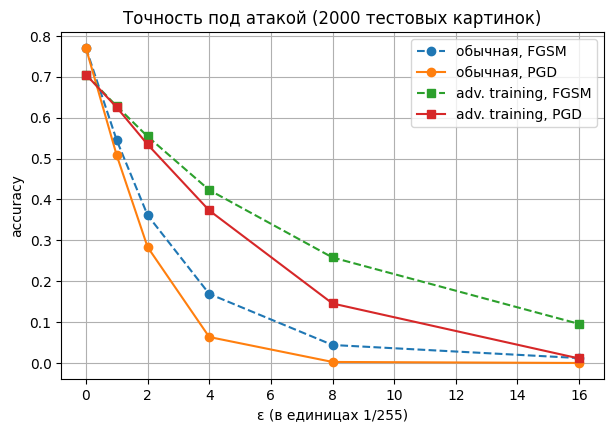

In [9]:
eps255 = [round(e * 255) for e in EPS]
plt.figure(figsize=(7, 4.5))
plt.plot(eps255, curve_clean['FGSM'], 'o--', label='обычная, FGSM')
plt.plot(eps255, curve_clean['PGD'], 'o-', label='обычная, PGD')
plt.plot(eps255, curve_adv['FGSM'], 's--', label='adv. training, FGSM')
plt.plot(eps255, curve_adv['PGD'], 's-', label='adv. training, PGD')
plt.xlabel('ε'); plt.ylabel('accuracy'); plt.grid(True); plt.legend()
plt.title('Точность под атакой'); plt.show()